# Replicating: *Computational evaluation using machine learning for analysis of membrane desalination process powered by solar energy*
Alanazi & Alharby, *Scientific Reports* (2025) 15:36384

**Goal:** replicate the MLP / XGBoost / Stacking(+ Jellyfish Optimizer) pipeline described in the paper and reproduce a results table analogous to their **Table 1**.

**Important note on exactness:** the paper's own code repo (https://github.com/TareqNafeaAlharby/perm_vol_prediction) only ships a pre-trained model for *inference* — it does **not** include the training script, the exact MLP architecture, the XGBoost search grid, the Jellyfish Optimizer settings, the stacking meta-learner, or random seeds. Those details are not published. This notebook implements the full pipeline **from the paper's written methodology** (Z-score outlier removal → log transform → 85/15 split → JO-tuned MLP & XGBoost → Stacking with a linear meta-model), so results will be **in the same ballpark and same qualitative pattern** (Stacking ≥ XGBoost ≈ MLP, R² in the 0.9–0.99 range) but not bit-for-bit identical to their published numbers — that's expected for any replication where hyperparameters/seeds aren't disclosed.

Dataset (45 obs, Time / Pressure / Permeate volume) is fetched directly from the paper's own repo, so it's identical to what they used.


## 1. Setup & imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
import shap
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Get the dataset
The dataset is published in the paper's repo: **https://github.com/TareqNafeaAlharby/perm_vol_prediction/blob/main/perm_vol.csv**
(45 observations: Time (min), Pressure (kgf/cm²), Permeate volume (mL) — matches the paper's stated `n=45`, extracted originally from Kumar, Mukil & Naveen (2024), *Digit. Chem. Eng.* 11, 100154 — ref. [15] in the paper).

If you're running this notebook somewhere with internet access, uncomment the download line. Otherwise, place `perm_vol.csv` in the same folder as this notebook.

In [2]:
# import urllib.request
# urllib.request.urlretrieve(
#     "https://raw.githubusercontent.com/TareqNafeaAlharby/perm_vol_prediction/main/perm_vol.csv",
#     "perm_vol.csv")

df = pd.read_csv("perm_vol.csv")
df.columns = ["Time", "Pressure", "Permeate"]
print(df.shape)
df.head()


(45, 3)


,Time,Pressure,Permeate
0,1,3,9
1,1,4,14
2,1,5,15
3,1,6,23
4,1,9,23


## 3. EDA — violin plots (Fig. 1) & histograms (Fig. 2) equivalents

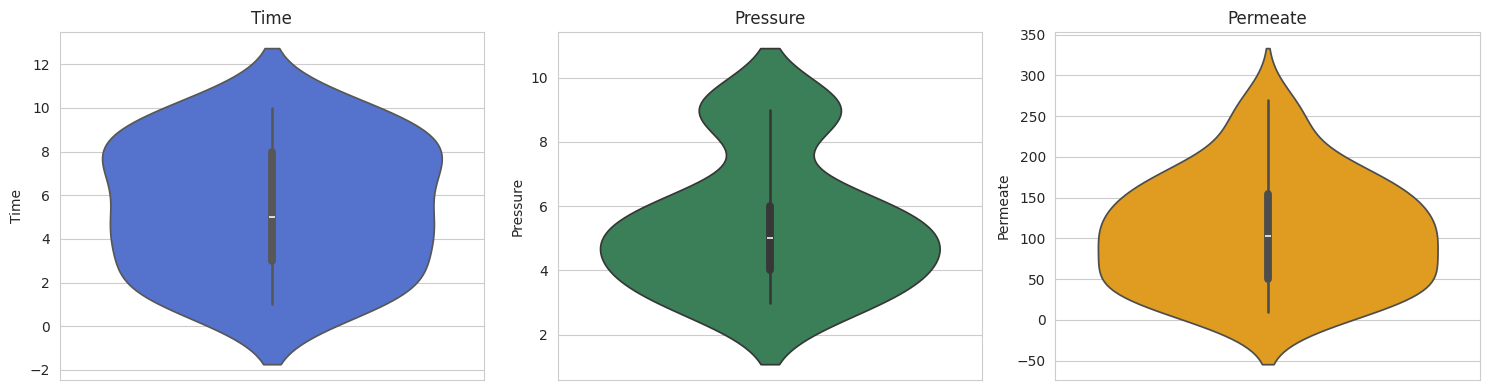

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["royalblue", "seagreen", "orange"]
for ax, col, color in zip(axes, df.columns, colors):
    sns.violinplot(y=df[col], ax=ax, color=color)
    ax.set_title(col)
plt.tight_layout()
plt.show()


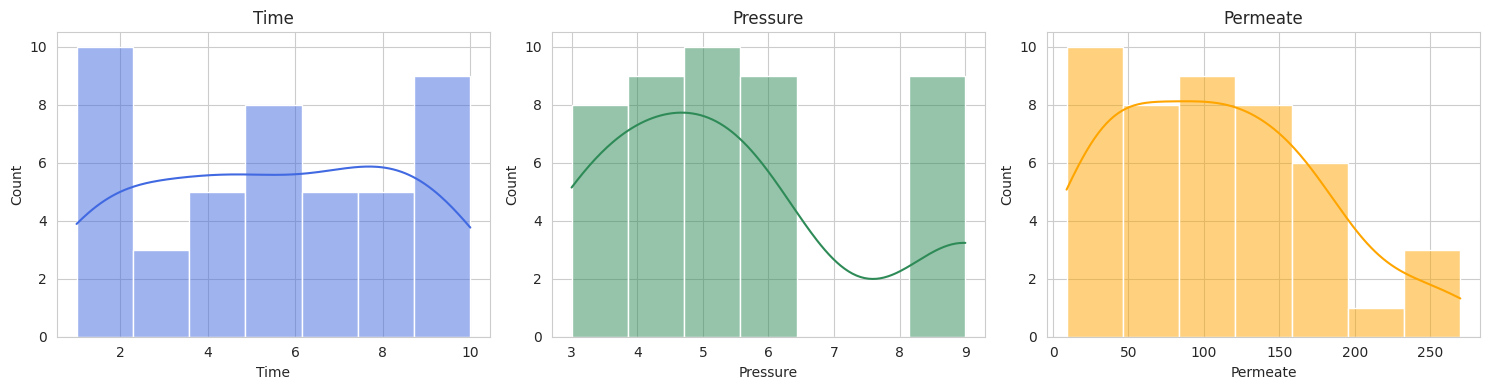

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, df.columns, colors):
    sns.histplot(df[col], kde=True, ax=ax, color=color)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## 4. Outlier detection — Z-score method
Paper: *"Data points with Z-scores exceeding 2.5 or 3 are typically regarded as outliers... we set a threshold, which is 3 standard deviations in this study."*

In [5]:
z = (df - df.mean()) / df.std()
outlier_mask = (z.abs() < 3).all(axis=1)
print("Outliers removed:", (~outlier_mask).sum())
df_clean = df[outlier_mask].reset_index(drop=True)
df_clean.shape


Outliers removed: 0


(45, 3)

## 5. Log transformation for normalization
Paper: $X' = \log(X + c)$, applied because the variable distributions (esp. Permeate volume) are right-skewed.

In [6]:
c = 1.0
df_log = np.log(df_clean + c)

X = df_log[["Time", "Pressure"]].values
y = df_log["Permeate"].values

def inv(y_log):
    return np.exp(y_log) - c


## 6. Train / test split (85% / 15%) + scaling

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
print("Train:", X_train_s.shape, " Test:", X_test_s.shape)


Train: (38, 2)  Test: (7, 2)


## 7. Jellyfish Optimizer (JO)
Custom implementation of Chou & Truong (2021), following the ocean-current / Type-A / Type-B swarm update rules described in the paper (Eqs. for $\vec d$, $X_i(t+1)$, and the $c(t) \geq 0.5$ branching in Fig. 3).

In [8]:
def jellyfish_optimizer(objective, bounds, n_pop=8, n_iter=10, seed=0, verbose=False):
    rgn = np.random.default_rng(seed)
    dim = len(bounds)
    lb = np.array([b[0] for b in bounds]); ub = np.array([b[1] for b in bounds])
    pop = lb + rgn.random((n_pop, dim)) * (ub - lb)
    fitness = np.array([objective(ind) for ind in pop])
    best_idx = np.argmin(fitness)
    best, best_fit = pop[best_idx].copy(), fitness[best_idx]

    for t in range(n_iter):
        c_t = abs((1 - t / n_iter) * (2 * rgn.random() - 1))   # time-control function c(t)
        mu = pop.mean(axis=0)
        for i in range(n_pop):
            if c_t >= 0.5:
                # --- Ocean current movement ---
                beta = 3 * rgn.random()
                pop[i] = pop[i] + rgn.random(dim) * (best - beta * rgn.random() * mu)
            else:
                if rgn.random() >= (1 - c_t):
                    # --- Type A: passive/individual motion ---
                    pop[i] = pop[i] + 0.1 * (ub - lb) * rgn.random(dim)
                else:
                    # --- Type B: active/swarm motion toward a random peer ---
                    j = rgn.integers(0, n_pop)
                    step = (pop[j] - pop[i]) if fitness[i] >= fitness[j] else (pop[i] - pop[j])
                    pop[i] = pop[i] + 0.1 * rgn.random(dim) * step
            pop[i] = np.clip(pop[i], lb, ub)
            fit_i = objective(pop[i])
            fitness[i] = fit_i
            if fit_i < best_fit:
                best_fit, best = fit_i, pop[i].copy()
        if verbose:
            print(f"  iter {t+1}/{n_iter}  best fitness={best_fit:.5f}")
    return best, best_fit


## 8. MLP — JO hyperparameter tuning
Search space: `(hidden_units_1, hidden_units_2, log10(alpha), log10(learning_rate_init))`.
Objective = 5-fold CV RMSE (on log scale).

In [9]:
def cv_rmse_mlp(params):
    h1, h2, alpha_exp, lr_exp = params
    h1, h2 = int(round(h1)), int(round(h2))
    hidden = (h1, h2) if h2 >= 2 else (h1,)
    model = MLPRegressor(hidden_layer_sizes=hidden, alpha=10**alpha_exp,
                          learning_rate_init=10**lr_exp, max_iter=800, random_state=SEED)
    preds = cross_val_predict(model, X_train_s, y_train, cv=kf)
    return np.sqrt(mean_squared_error(y_train, preds))

mlp_bounds = [(4, 32), (0, 16), (-5, -1), (-4, -1.5)]
print("Tuning MLP with Jellyfish Optimizer...")
best_mlp_params, best_mlp_fit = jellyfish_optimizer(cv_rmse_mlp, mlp_bounds, n_pop=8, n_iter=10, seed=SEED, verbose=True)
print("Best MLP params:", best_mlp_params)


Tuning MLP with Jellyfish Optimizer...


  iter 1/10  best fitness=0.19629


  iter 2/10  best fitness=0.18249


  iter 3/10  best fitness=0.18249


  iter 4/10  best fitness=0.15348


...

  iter 6/10  best fitness=0.14950


  iter 7/10  best fitness=0.14935


  iter 8/10  best fitness=0.14935


  iter 9/10  best fitness=0.14740


  iter 10/10  best fitness=0.14740
Best MLP params: [18.11423797  7.70639923 -1.83537074 -1.5       ]


## 9. XGBoost — JO hyperparameter tuning
Search space: `(n_estimators, max_depth, log10(learning_rate), subsample)`.

In [10]:
def cv_rmse_xgb(params):
    n_est, max_depth, lr_exp, subsample = params
    model = XGBRegressor(n_estimators=int(round(n_est)), max_depth=int(round(max_depth)),
                          learning_rate=10**lr_exp, subsample=subsample,
                          random_state=SEED, verbosity=0)
    preds = cross_val_predict(model, X_train_s, y_train, cv=kf)
    return np.sqrt(mean_squared_error(y_train, preds))

xgb_bounds = [(30, 300), (2, 6), (-2.3, -0.5), (0.6, 1.0)]
print("Tuning XGBoost with Jellyfish Optimizer...")
best_xgb_params, best_xgb_fit = jellyfish_optimizer(cv_rmse_xgb, xgb_bounds, n_pop=8, n_iter=10, seed=SEED, verbose=True)
print("Best XGB params:", best_xgb_params)


Tuning XGBoost with Jellyfish Optimizer...


  iter 1/10  best fitness=0.19382


  iter 2/10  best fitness=0.19382


  iter 3/10  best fitness=0.19382


  iter 4/10  best fitness=0.19382


...

  iter 6/10  best fitness=0.19382


  iter 7/10  best fitness=0.19382


  iter 8/10  best fitness=0.19382


  iter 9/10  best fitness=0.19382


  iter 10/10  best fitness=0.19382
Best XGB params: [200.81757633   2.43883533  -0.70789048   0.85825764]


## 10. Fit final MLP & XGBoost with JO-tuned hyperparameters

In [11]:
h1, h2 = int(round(best_mlp_params[0])), int(round(best_mlp_params[1]))
mlp_final = MLPRegressor(hidden_layer_sizes=(h1, h2) if h2 >= 2 else (h1,),
                          alpha=10**best_mlp_params[2], learning_rate_init=10**best_mlp_params[3],
                          max_iter=5000, random_state=SEED)

xgb_final = XGBRegressor(n_estimators=int(round(best_xgb_params[0])),
                          max_depth=int(round(best_xgb_params[1])),
                          learning_rate=10**best_xgb_params[2], subsample=best_xgb_params[3],
                          random_state=SEED, verbosity=0)

mlp_final.fit(X_train_s, y_train)
xgb_final.fit(X_train_s, y_train)

mlp_cv = cross_val_predict(MLPRegressor(**mlp_final.get_params()), X_train_s, y_train, cv=kf)
xgb_cv = cross_val_predict(XGBRegressor(**xgb_final.get_params()), X_train_s, y_train, cv=kf)
print("Done.")


Done.


## 11. Stacking ensemble (MLP + XGBoost, linear meta-model)
Following the paper's 4-step procedure: base models trained → out-of-fold (CV) predictions used to train a meta-model → meta-model combines base-model outputs for the final prediction.

In [12]:
meta_train_X = np.column_stack([mlp_cv, xgb_cv])
meta_model = LinearRegression()
meta_model.fit(meta_train_X, y_train)

def stack_predict(Xs):
    p1 = mlp_final.predict(Xs)
    p2 = xgb_final.predict(Xs)
    return meta_model.predict(np.column_stack([p1, p2]))

stack_cv_pred = meta_model.predict(meta_train_X)


## 12. Results table — replicates paper's Table 1

In [13]:
def metrics(y_true_log, y_pred_log):
    yt, yp = inv(y_true_log), inv(y_pred_log)
    return r2_score(yt, yp), np.sqrt(mean_squared_error(yt, yp)), mean_absolute_error(yt, yp)

rows = []
for name, model, cvp in [("MLP", mlp_final, mlp_cv), ("XGBoost", xgb_final, xgb_cv)]:
    tr = metrics(y_train, model.predict(X_train_s))
    cv = metrics(y_train, cvp)
    te = metrics(y_test, model.predict(X_test_s))
    rows.append([name, *tr, *cv, *te])

tr = metrics(y_train, stack_predict(X_train_s))
cv = metrics(y_train, stack_cv_pred)
te = metrics(y_test, stack_predict(X_test_s))
rows.append(["Stacking", *tr, *cv, *te])

results = pd.DataFrame(rows, columns=["Model","Train_R2","Train_RMSE","Train_MAE",
                                       "CV_R2","CV_RMSE","CV_MAE","Test_R2","Test_RMSE","Test_MAE"])
results.round(5)


,Model,Train_R2,Train_RMSE,Train_MAE,CV_R2,CV_RMSE,CV_MAE,Test_R2,Test_RMSE,Test_MAE
0,MLP,0.96212,12.95505,8.00247,0.92449,18.29192,11.69389,0.94491,14.99484,12.40253
1,XGBoost,0.99830,2.74764,1.88505,0.92940,17.68709,11.17065,0.92540,17.44815,11.69422
2,Stacking,0.97592,10.32952,6.26497,0.93566,16.88478,10.68500,0.94304,15.24643,11.88526


**Paper's Table 1 (for comparison):**

| Metric | MLP | XGBoost | Stacking |
|---|---|---|---|
| Train R² | 0.96340 | 0.95768 | 0.99060 |
| Train RMSE | 11.9418 | 12.8410 | 6.05188 |
| Train MAE | 9.00181 | 10.1286 | 4.17026 |
| CV R² | 0.95062 | 0.87272 | 0.97627 |
| Test R² | 0.96242 | 0.90211 | 0.99043 |
| Test RMSE | 12.2469 | 19.7669 | 6.17921 |
| Test MAE | 9.60500 | 14.6429 | 5.90072 |


## 13. Predicted vs Actual (Figs. 4–6 equivalents)

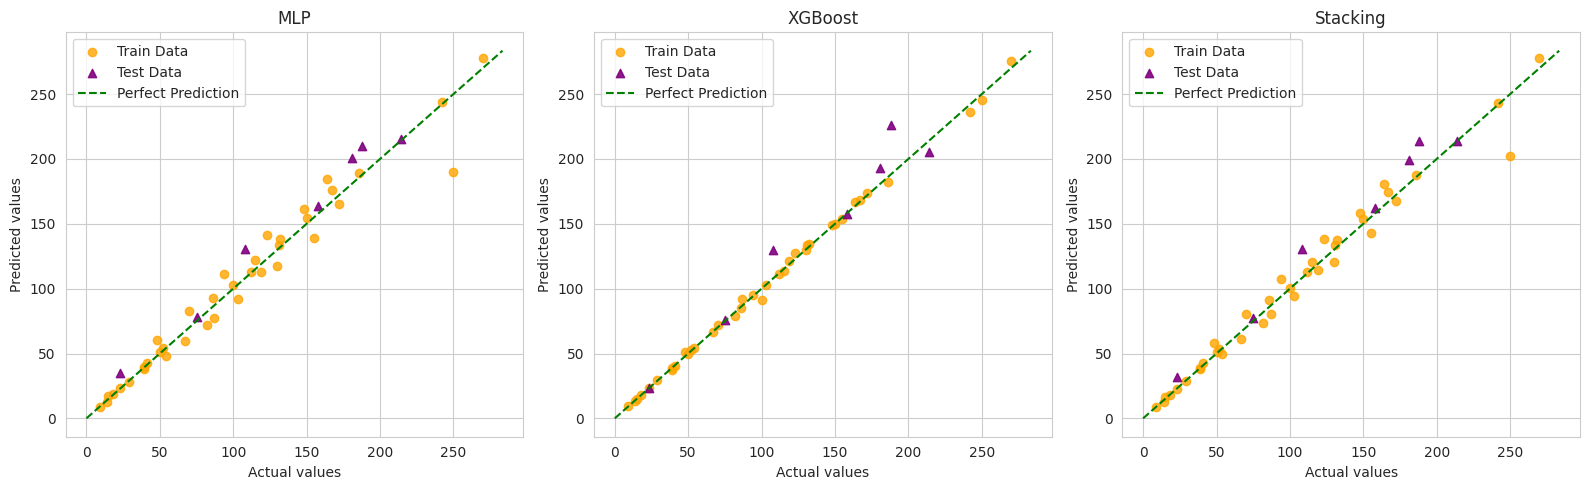

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
model_preds = {
    "MLP": (mlp_final.predict(X_train_s), mlp_final.predict(X_test_s)),
    "XGBoost": (xgb_final.predict(X_train_s), xgb_final.predict(X_test_s)),
    "Stacking": (stack_predict(X_train_s), stack_predict(X_test_s)),
}
for ax, (name, (tr_pred, te_pred)) in zip(axes, model_preds.items()):
    y_train_orig, y_test_orig = inv(y_train), inv(y_test)
    tr_pred_orig, te_pred_orig = inv(tr_pred), inv(te_pred)
    ax.scatter(y_train_orig, tr_pred_orig, color="orange", label="Train Data", alpha=0.8)
    ax.scatter(y_test_orig, te_pred_orig, color="purple", marker="^", label="Test Data", alpha=0.9)
    lims = [0, max(y.max() for y in [y_train_orig, y_test_orig]) * 1.05]
    ax.plot(lims, lims, "g--", label="Perfect Prediction")
    ax.set_xlabel("Actual values"); ax.set_ylabel("Predicted values"); ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()


## 14. Residual plot — Stacking model (Fig. 7 equivalent)

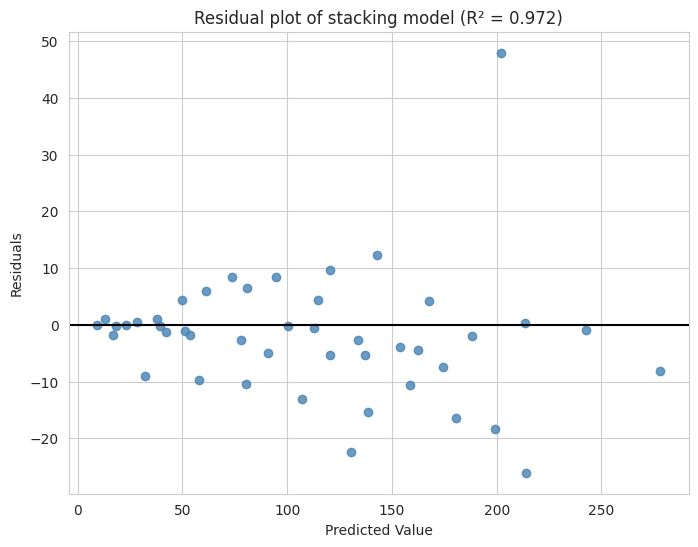

In [15]:
all_pred = inv(np.concatenate([stack_predict(X_train_s), stack_predict(X_test_s)]))
all_true = inv(np.concatenate([y_train, y_test]))
residuals = all_true - all_pred

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(all_pred, residuals, color="steelblue", alpha=0.8)
ax.axhline(0, color="black")
ax.set_xlabel("Predicted Value"); ax.set_ylabel("Residuals")
r2_all = r2_score(all_true, all_pred)
ax.set_title(f"Residual plot of stacking model (R² = {r2_all:.3f})")
plt.show()


## 15. Individual & joint effects of Time / Pressure (Figs. 8–9 equivalents)

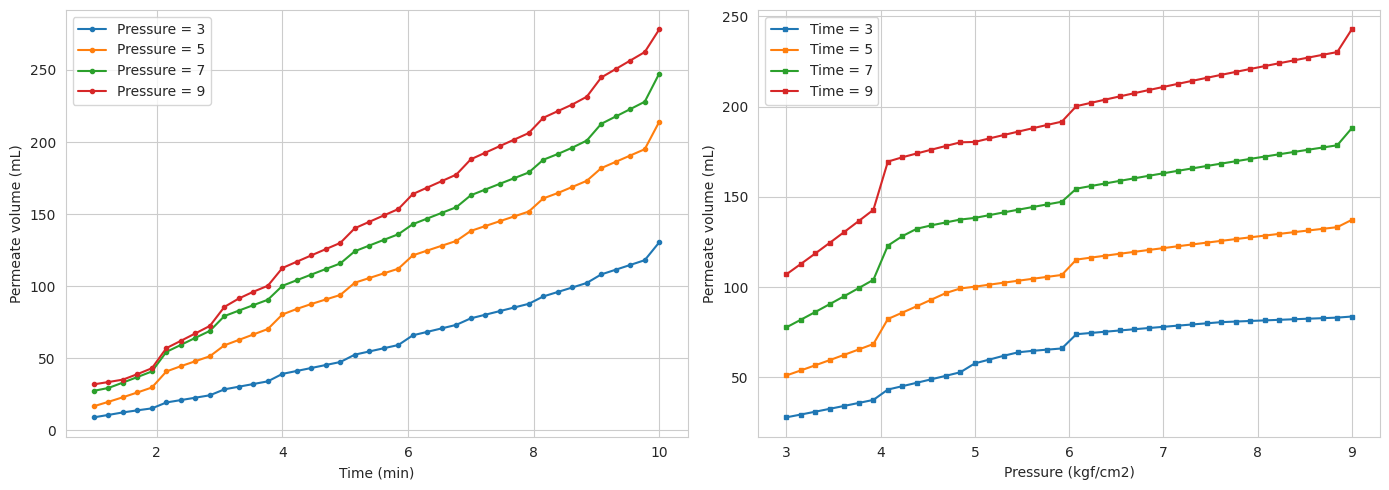

In [16]:
time_grid = np.linspace(df_clean.Time.min(), df_clean.Time.max(), 40)
pressure_levels = [3, 5, 7, 9]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for p in pressure_levels:
    grid = np.log(np.column_stack([time_grid, np.full_like(time_grid, p)]) + c)
    grid_s = scaler.transform(grid)
    pred = inv(stack_predict(grid_s))
    axes[0].plot(time_grid, pred, marker="o", markersize=3, label=f"Pressure = {p}")
axes[0].set_xlabel("Time (min)"); axes[0].set_ylabel("Permeate volume (mL)"); axes[0].legend()

pressure_grid = np.linspace(df_clean.Pressure.min(), df_clean.Pressure.max(), 40)
for tval in [3, 5, 7, 9]:
    grid = np.log(np.column_stack([np.full_like(pressure_grid, tval), pressure_grid]) + c)
    grid_s = scaler.transform(grid)
    pred = inv(stack_predict(grid_s))
    axes[1].plot(pressure_grid, pred, marker="s", markersize=3, label=f"Time = {tval}")
axes[1].set_xlabel("Pressure (kgf/cm2)"); axes[1].set_ylabel("Permeate volume (mL)"); axes[1].legend()
plt.tight_layout()
plt.show()


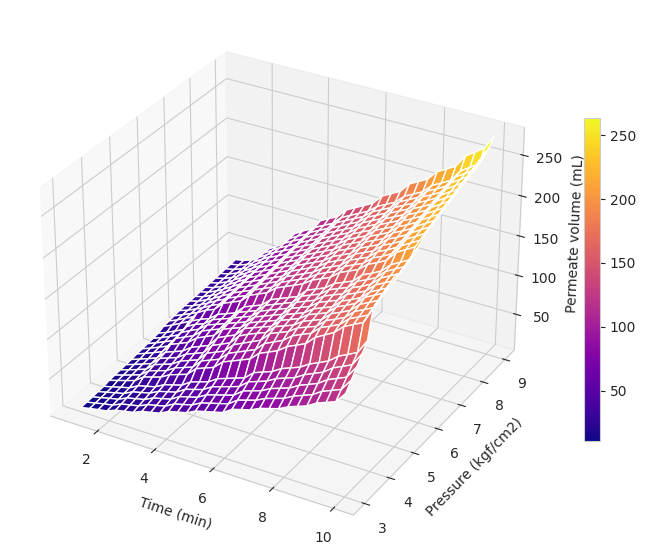

In [17]:
from mpl_toolkits.mplot3d import Axes3D
T_mesh, P_mesh = np.meshgrid(np.linspace(df_clean.Time.min(), df_clean.Time.max(), 30),
                              np.linspace(df_clean.Pressure.min(), df_clean.Pressure.max(), 30))
grid_flat = np.log(np.column_stack([T_mesh.ravel(), P_mesh.ravel()]) + c)
grid_flat_s = scaler.transform(grid_flat)
Z = inv(stack_predict(grid_flat_s)).reshape(T_mesh.shape)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(T_mesh, P_mesh, Z, cmap="plasma")
ax.set_xlabel("Time (min)"); ax.set_ylabel("Pressure (kgf/cm2)"); ax.set_zlabel("Permeate volume (mL)")
fig.colorbar(surf, shrink=0.6)
plt.show()


## 16. SHAP analysis (Fig. 10 equivalent)

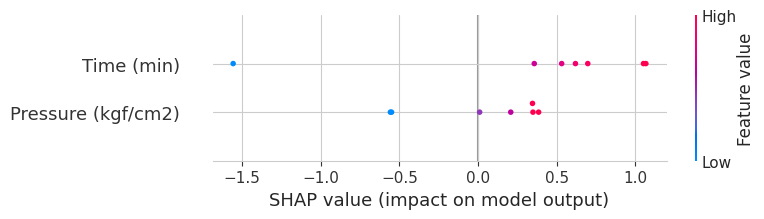

In [18]:
explainer = shap.TreeExplainer(xgb_final, feature_perturbation="tree_path_dependent")
shap_values = explainer(X_test_s)
shap_values.feature_names = ["Time (min)", "Pressure (kgf/cm2)"]
shap.summary_plot(shap_values, features=X_test, feature_names=["Time (min)", "Pressure (kgf/cm2)"])


## 17. Comparison with baseline models (Fig. 11 equivalent)
The paper compares against baseline models (DTR, KNN, RFR, SVR) from Kumar et al. (2024) [15]. We fit those baselines ourselves on the same split for a fair, self-contained comparison (the paper's own baseline numbers for [15] aren't reproducible from the text alone since that's a different study's models/data split).

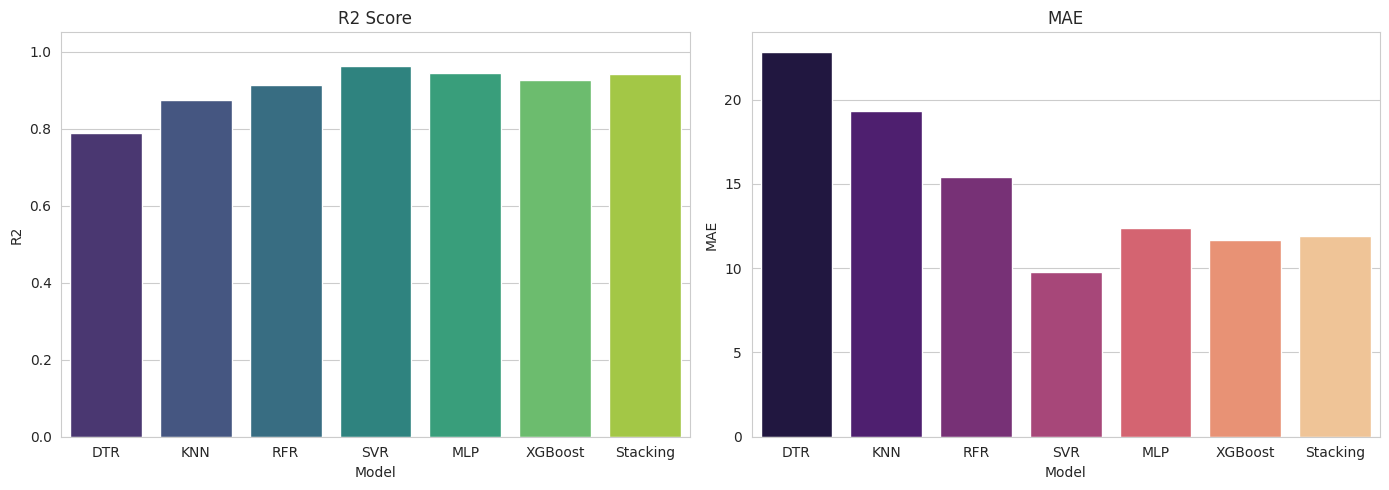

,Model,R2,MAE
0,DTR,0.789341,22.857143
1,KNN,0.874527,19.344398
2,RFR,0.912869,15.394453
3,SVR,0.963742,9.802290
4,MLP,0.944905,12.402535
5,XGBoost,0.925402,11.694215
6,Stacking,0.943041,11.885265


In [19]:
baselines = {
    "DTR": DecisionTreeRegressor(random_state=SEED),
    "KNN": KNeighborsRegressor(n_neighbors=3),
    "RFR": RandomForestRegressor(random_state=SEED, n_estimators=200),
    "SVR": SVR(),
}

comp_rows = []
for name, model in baselines.items():
    model.fit(X_train_s, y_train)
    r2, rmse, mae = metrics(y_test, model.predict(X_test_s))
    comp_rows.append([name, r2, mae])

for name in ["MLP", "XGBoost", "Stacking"]:
    r = results[results.Model == name].iloc[0]
    comp_rows.append([name, r.Test_R2, r.Test_MAE])

comp_df = pd.DataFrame(comp_rows, columns=["Model", "R2", "MAE"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=comp_df, x="Model", y="R2", ax=axes[0], palette="viridis")
axes[0].set_title("R2 Score"); axes[0].set_ylim(0, 1.05)
sns.barplot(data=comp_df, x="Model", y="MAE", ax=axes[1], palette="magma")
axes[1].set_title("MAE")
plt.tight_layout()
plt.show()
comp_df


## 18. Notes / what to tune for closer agreement with the paper
- Increase `n_pop` / `n_iter` in the Jellyfish Optimizer calls (cells 8 & 9) for a more thorough hyperparameter search (slower).
- Try different meta-learners for stacking (e.g. `Ridge`, a small `XGBRegressor` as meta-model) — the paper doesn't specify which one it used.
- Try different `hidden_layer_sizes` search ranges for the MLP, or swap `sklearn.MLPRegressor` for a Keras/PyTorch MLP if you want closer control over architecture/activations (`δ₁`, `δ₂` in the paper's formula).
- The paper doesn't state its CV fold count; we used 5-fold — try 10-fold if that's closer to what "cross-validation" meant there.
- With only 45 rows, results are fairly sensitive to the exact train/test split (`random_state`) — try a few seeds and report the average if you need more stable numbers.
